In [1]:
%pip install numpy matplotlib scipy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import kalman
kalman.set_debug(0)

import kalman.runtime.chrono as chrono
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
plt.rcParams["savefig.pad_inches"] = 0.05

Note: you may need to restart the kernel to use updated packages.


# Power Grid Harmonic Tracking

The mains voltage should be a pure 50 Hz sine. Loads such as rectifiers, motor drives and chargers draw current in bursts, and this adds **harmonics**: sines at multiples of 50 Hz, which distort the waveform.

The amount of distortion is measured by the **total harmonic distortion** (THD), the size of all harmonics together relative to the 50 Hz component. Grid standards limit it: IEEE 519 allows 8 % on low-voltage networks.

A Fourier-transform meter gives one value per analysis window. The Kalman filter in this notebook follows the amplitude and phase of every harmonic sample by sample, and reports an uncertainty for each. That is what an active filter needs to cancel the harmonics, and what a monitor needs to detect a faulty load.

## Step 1 — The Phasor

A sine $v(t) = V\cos(2\pi f_0 t + \varphi)$ is fixed by two numbers, its amplitude $V$ and its phase $\varphi$. They are kept together as a **phasor**, the pair $[\mathrm{Re},\,\mathrm{Im}] = [V\cos\varphi,\; V\sin\varphi]$, which can be drawn as an arrow of length $V$ at angle $\varphi$.

A distorted voltage is a sum of harmonics, each with its own phasor:

$$v(t) = \sum_{k} \mathrm{Re}_k \cos(2\pi k f_0 t) - \mathrm{Im}_k \sin(2\pi k f_0 t)$$

The example grid has a 50 Hz fundamental of amplitude 325 V, which is the peak of the usual 230 V mains (230 V is the root-mean-square value, the peak divided by √2), a third harmonic of 15 V and a fifth of 5 V.

`02_Oscillators.ipynb` introduces phasors in more detail.

In [2]:
from kalman.apps.resonators.powergrids import plot_phasor_diagram

f0 = 50.0   # fundamental frequency [Hz]
# (amplitude [V], phase [rad]) of the fundamental, the 3rd and the 5th harmonic
phasors = [(325.0, 0.0), (15.0, np.pi / 4), (5.0, np.pi / 3)]

plot_phasor_diagram(f0, phasors)

## Step 2 — Why Only Odd Harmonics Appear

A healthy AC waveform has **half-wave symmetry**: its negative half-cycle is the mirror image of the positive one, $v(t + T_0/2) = -v(t)$, with $T_0 = 1/f_0$ the period. An even harmonic repeats exactly after half a period, so it cannot satisfy this. Only the odd harmonics (H1, H3, H5, …) remain.

A load that treats the two half-cycles differently breaks the symmetry and adds even harmonics. A half-wave rectifier, which conducts during one half-cycle only, is the standard example.

This gives a simple check: track all harmonics and watch H2 and H4. They should stay near zero, and an even harmonic that appears points to a fault. Step 8 uses this.

The cell compares the spectrum of the healthy grid with that of a grid carrying a second harmonic of 6.5 V, 2 % of the fundamental.

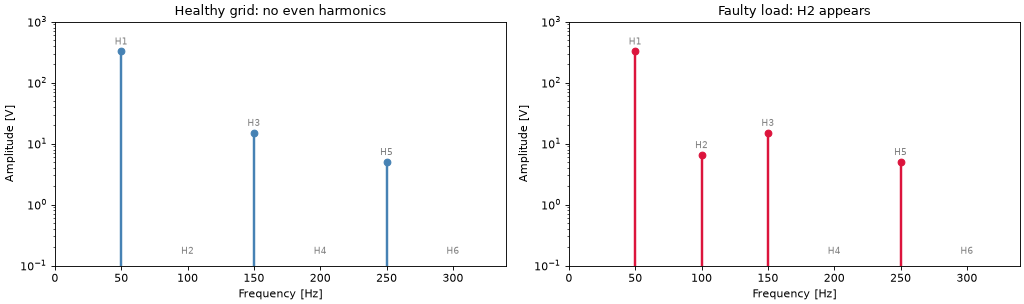

healthy:  H1 = 325 V   H2 = 0.0 V   H3 = 15 V
faulty :  H1 = 325 V   H2 = 6.5 V   H3 = 15 V


In [3]:
from numpy.fft import rfft, rfftfreq

fs_demo = 1024.0   # sample rate [Hz]
T_demo = 4.0       # duration [s]
t_d = np.arange(int(T_demo * fs_demo)) / fs_demo
V1, V3, V5 = 325.0, 15.0, 5.0   # amplitudes [V]

# Healthy: odd harmonics only
v_odd = (V1 * np.cos(2 * np.pi * f0 * t_d) +
         V3 * np.cos(2 * np.pi * 3 * f0 * t_d + np.pi / 4) +
         V5 * np.cos(2 * np.pi * 5 * f0 * t_d + np.pi / 3))

# Faulty: a second harmonic is added
V2_fault = 6.5     # [V]
v_fault = v_odd + V2_fault * np.cos(2 * np.pi * 2 * f0 * t_d + 0.8)

# Amplitude of harmonic k, read from the Fourier transform
def harmonic_amplitude(signal, k):
    return np.abs(rfft(signal)[int(k * f0 * T_demo)]) * 2 / len(signal)

harmonics_k = np.arange(1, 7)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, v, title, col in zip(axes, [v_odd, v_fault],
                             ["Healthy grid: no even harmonics", "Faulty load: H2 appears"],
                             ["steelblue", "crimson"]):
    amps = np.array([harmonic_amplitude(v, k) for k in harmonics_k])
    markerline, stemlines, baseline = ax.stem(harmonics_k * f0, amps, basefmt="gray")
    plt.setp(stemlines, color=col, linewidth=2.2)
    plt.setp(markerline, color=col, markersize=6)
    for k, a in zip(harmonics_k, amps):
        ax.text(k * f0, max(a, 0.12) * 1.3, f"H{k}", ha="center", fontsize=8, color="gray")
    ax.set_yscale("log"); ax.set_ylim(0.1, 1000)
    ax.set_xlim(0, 340)
    ax.set_xlabel("Frequency [Hz]")
    ax.set_ylabel("Amplitude [V]")
    ax.set_title(title)
plt.tight_layout()
plt.show()

for name, v in [("healthy", v_odd), ("faulty ", v_fault)]:
    print(f"{name}:  H1 = {harmonic_amplitude(v, 1):.0f} V   H2 = {harmonic_amplitude(v, 2):.1f} V   H3 = {harmonic_amplitude(v, 3):.0f} V")

## Step 3 — The Kalman Filter as a Phasor Meter

The filter works on the raw measured voltage.

**State.** One phasor per harmonic, stacked: $\mathbf x = [\mathrm{Re}_1, \mathrm{Im}_1,\ \mathrm{Re}_2, \mathrm{Im}_2,\ \dots,\ \mathrm{Re}_N, \mathrm{Im}_N]$, so $2N$ numbers for $N$ harmonics.

**Dynamics.** A steady sine has a constant phasor, so $F = I$. A small process noise lets the phasors drift slowly; without it the filter would stop responding to changes.

**Measurement.** One number per sample, the voltage. It is the sum over the harmonics written in Step 1, which is $\mathbf z = H(t)\,\mathbf x$ with a measurement matrix that changes with time:

$$H(t) = [\cos\omega_1 t,\ -\sin\omega_1 t,\ \cos\omega_2 t,\ -\sin\omega_2 t,\ \dots],\qquad \omega_k = 2\pi k f_0$$

All phasors are estimated together from the one voltage. This matters: the 325 V fundamental is accounted for by its own phasor, so nothing of it is left over to be mistaken for a small harmonic next to it.

This is the **lab-frame** form of `02_Oscillators.ipynb`, Step 1. It suits a few strong lines spread over a wide band.

## Step 4 — `PhasorOscillatorModel`: Any Set of Frequencies

The general model tracks any list of frequencies in a real signal; they need not be harmonics. Here it is given two unrelated tones, at 60 Hz and 173.2 Hz, with amplitudes 1 and 0.5, in noise of standard deviation 0.05.

Its noise arguments are standard deviations, in the units of the signal: `measurement_uncertainty` for the noise on each sample, `process_uncertainty` for the drift of each phasor component per step, and `p0_std` for how far the initial guess (zero) may be from the truth.

state: n = 4 (two phasors),  measurement: m = 1 (the signal)
amplitudes over the second half: [0.999 0.498]   (true: 1.0, 0.5)


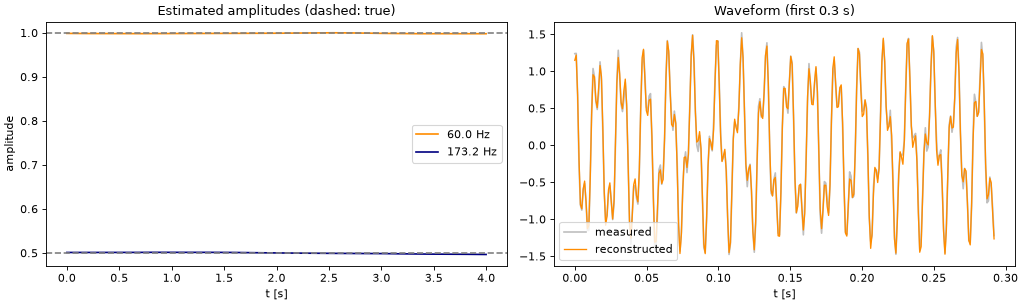

In [4]:
from kalman.apps.resonators.oscillators import PhasorOscillatorModel

np.random.seed(3)
fs_demo, T_demo = 1024.0, 4.0
t_demo = np.arange(int(T_demo * fs_demo)) / fs_demo
f_a, f_b = 60.0, 173.2      # [Hz]
A_a, A_b = 1.0, 0.5
sig = (A_a * np.cos(2 * np.pi * f_a * t_demo + 0.4)
       + A_b * np.cos(2 * np.pi * f_b * t_demo - 1.1)
       + 0.05 * np.random.randn(len(t_demo)))

phasor = PhasorOscillatorModel("demo", [f_a, f_b], fs=fs_demo,
                               measurement_uncertainty=0.05,    # noise std per sample
                               process_uncertainty=1e-4,        # drift per step (std)
                               p0_std=10.0)                     # initial uncertainty (std)
rec_p = phasor.filter(sig, smooth=True)
amp_p = phasor.amplitudes(rec_p)
recon_p = phasor.reconstruct(rec_p)

print(f"state: n = {phasor.n} (two phasors),  measurement: m = {phasor.m} (the signal)")
print("amplitudes over the second half:", np.round(amp_p[len(t_demo) // 2:].mean(axis=0), 3),
      f"  (true: {A_a}, {A_b})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(t_demo, amp_p[:, 0], color="darkorange", label=f"{f_a} Hz")
axes[0].plot(t_demo, amp_p[:, 1], color="navy", label=f"{f_b} Hz")
axes[0].axhline(A_a, ls="--", color="gray")
axes[0].axhline(A_b, ls="--", color="gray")
axes[0].set_title("Estimated amplitudes (dashed: true)")
axes[0].set_xlabel("t [s]")
axes[0].set_ylabel("amplitude")
axes[0].legend()

n_preview = 300
axes[1].plot(t_demo[:n_preview], sig[:n_preview], color="gray", alpha=0.5, label="measured")
axes[1].plot(t_demo[:n_preview], recon_p[:n_preview], color="darkorange", lw=1.2, label="reconstructed")
axes[1].set_title("Waveform (first 0.3 s)")
axes[1].set_xlabel("t [s]")
axes[1].legend()
plt.tight_layout()
plt.show()

## Step 5 — A Synthetic Grid Signal

The test signal has known content:

- fundamental: 50 Hz, amplitude 325 V (230 V RMS);
- third harmonic: 150 Hz, 15 V;
- fifth harmonic: 250 Hz, 5 V;
- measurement noise of standard deviation 10 V.

There are no even harmonics. The filter will track H1 to H5, and H2 and H4 should come out near zero.

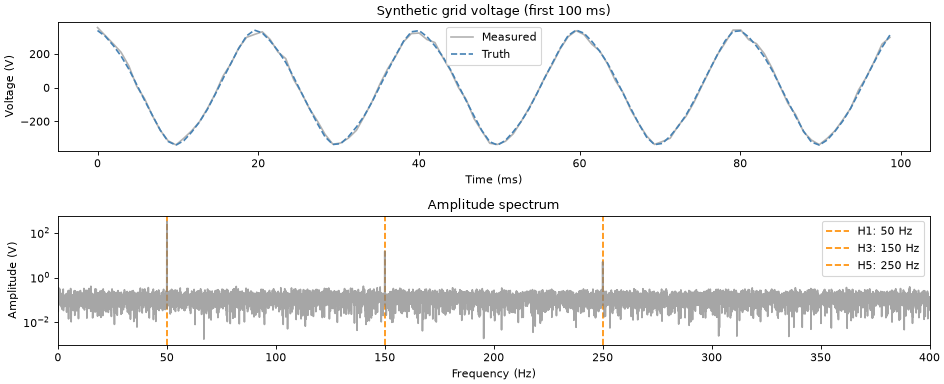

In [5]:
f0 = 50.0     # [Hz]
fs = 1024.0   # sample rate [Hz]
T = 20.0      # duration [s]
t = np.arange(int(T * fs)) / fs

A1, phi1 = 325.0, 0.0           # amplitude [V], phase [rad]
A3, phi3 = 15.0, np.pi / 4
A5, phi5 = 5.0, np.pi / 3

v_clean = (A1 * np.cos(2 * np.pi * f0 * t + phi1)
         + A3 * np.cos(2 * np.pi * 3 * f0 * t + phi3)
         + A5 * np.cos(2 * np.pi * 5 * f0 * t + phi5))
noise_std = 10.0                # [V]
np.random.seed(0)
v_noisy = v_clean + np.random.normal(0, noise_std, len(t))

fig, axes = plt.subplots(2, 1, figsize=(12, 5))
n_show = int(0.1 * fs)
axes[0].plot(t[:n_show] * 1e3, v_noisy[:n_show], alpha=0.6, color="gray", label="Measured")
axes[0].plot(t[:n_show] * 1e3, v_clean[:n_show], "--", color="steelblue", label="Truth")
axes[0].set_xlabel("Time (ms)")
axes[0].set_ylabel("Voltage (V)")
axes[0].set_title("Synthetic grid voltage (first 100 ms)")
axes[0].legend()

freqs_d = rfftfreq(len(t), 1 / fs)
spectrum = np.abs(rfft(v_noisy)) * 2 / len(t)
axes[1].semilogy(freqs_d, spectrum, color="gray", alpha=0.7)
for freq_hz, label in [(50, "H1"), (150, "H3"), (250, "H5")]:
    axes[1].axvline(freq_hz, ls="--", color="darkorange", lw=1.5, zorder=-1, label=f"{label}: {freq_hz} Hz")
axes[1].set_xlim(0, 400)
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Amplitude (V)")
axes[1].set_title("Amplitude spectrum")
axes[1].legend()
plt.tight_layout()
plt.show()

## Step 6 — `PowerGridStateModel`: Harmonics of the Mains

`PowerGridStateModel` is the model of Step 4 with its frequencies set to the harmonics of `f0`. We track five of them, H1 to H5.

The filter starts from what an engineer would know in advance: a fundamental of 325 V and no harmonics. It then has to find H3 and H5 and keep H2 and H4 near zero. `measurement_uncertainty` is the 10 V noise, and `process_uncertainty` = 0.01 V lets each phasor drift by 0.01 V per sample.

PowerGridStateModel(KalmanModel) @ fs=1024.0Hz
    Power Grid Harmonic Tracker (v4.0)
        Mains specialization of PhasorOscillatorModel:
        joint lab-frame phasor estimator tracking
        N harmonics of a 50/60 Hz grid from the
        scalar voltage — all harmonics coupled
        through one measurement, so absent (even)
        harmonics read ≈ 0.
    Dimensions Summary:
        State Vector....................................: 10 dims (PhasorState<REAL, IMAG>)
        Observation.....................................: 1 dim  (PowerGridObservable<VOLTAGE>)
        Control Input...................................: 0 dims
    Initial State:
        State Vector (x0)...............................: 10x1 dims
        State Covariance (P0)...........................: 10x10 dims



amplitudes over the last 2 s [V]: [324.9   0.4  14.6   0.4   4.7]   (true: 325, 0, 15, 0, 5)


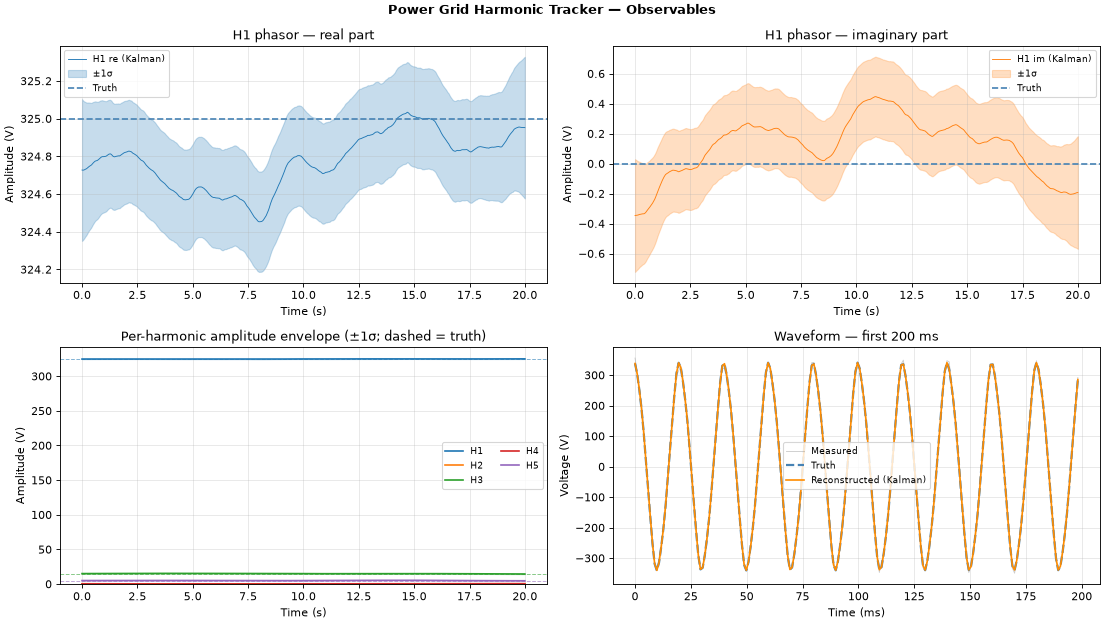

In [6]:
from kalman.apps.resonators.powergrids import PowerGridStateModel

grid = PowerGridStateModel("L1", f0=f0, harmonics=5, fs=fs,
                           measurement_uncertainty=noise_std,   # noise std [V]
                           process_uncertainty=0.01)            # drift per sample (std) [V]
grid.initial_state([[A1, 0],   # H1: the nominal mains voltage
                    [0,  0],   # H2
                    [0,  0],   # H3
                    [0,  0],   # H4
                    [0,  0]])  # H5
grid.print()

record = grid.filter(v_noisy, smooth=True, reset=True)

grid.plot(record, measured=v_noisy, truth=v_clean,
          true_amplitudes=[A1, 0, A3, 0, A5])

amplitudes, sigma_amp = grid.harmonic_envelope(record)   # amplitude of each harmonic and its standard deviation
tail = slice(-len(t) // 10, None)                        # last 2 s
print("amplitudes over the last 2 s [V]:", np.round(amplitudes[tail].mean(axis=0), 1),
      f"  (true: {A1:.0f}, 0, {A3:.0f}, 0, {A5:.0f})")

### Waveform Replay

The player slides a 200 ms window along the signal and shows the measured voltage, the true voltage and the filter's reconstruction.

In [7]:
grid.plot(record, interactive=True, measured=v_noisy, truth=v_clean, window_ms=200)

## Step 6b — Removing the Harmonics: `subtract_voltage()`

Once the phasors are known, the tracked content can be rebuilt as a waveform and subtracted from the measurement. `subtract_voltage(measured, record)` does this and returns what is left. An active harmonic filter works the same way: it injects the reconstructed harmonics with the opposite sign.

The cell does it twice. The forward filter (`smooth=False`) uses only past samples, as a real-time device must. The smoother (`smooth=True`) adds a backward pass, so each estimate also uses later samples.

Both leave only the 10 V noise. On this steady signal the forward filter has found the harmonics within the first tenths of a second, and after that the smoother has nothing to add.

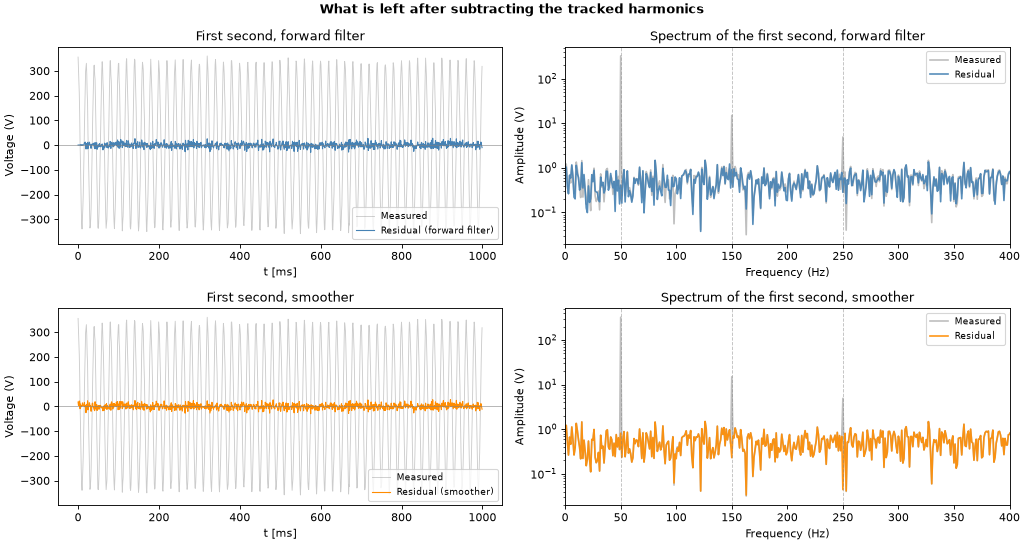

residual std over the last 2 s:  forward filter 9.90 V,  smoother 9.93 V   (noise: 10 V)


In [8]:
record_causal = grid.filter(v_noisy, smooth=False, reset=True)   # forward filter only

residual_smooth = grid.subtract_voltage(v_noisy, record)
residual_causal = grid.subtract_voltage(v_noisy, record_causal)

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
fig.suptitle("What is left after subtracting the tracked harmonics", fontweight="bold")

n_show = int(fs)                              # first second
freqs_w = rfftfreq(n_show, 1 / fs)

runs = [
    (residual_causal, "forward filter", "steelblue"),
    (residual_smooth, "smoother",       "darkorange"),
]
for row, (res, label, color) in enumerate(runs):
    ax = axes[row, 0]
    ax.plot(t[:n_show] * 1e3, v_noisy[:n_show], color="gray", alpha=0.4, lw=0.8, label="Measured")
    ax.plot(t[:n_show] * 1e3, res[:n_show], color=color, lw=1.0, label=f"Residual ({label})")
    ax.axhline(0, color="gray", lw=0.5)
    ax.set_xlabel("t [ms]")
    ax.set_ylabel("Voltage (V)")
    ax.set_title(f"First second, {label}")
    ax.legend(fontsize=8)

    ax = axes[row, 1]
    spec_before = np.abs(rfft(v_noisy[:n_show])) * 2 / n_show
    spec_after = np.abs(rfft(res[:n_show])) * 2 / n_show
    ax.semilogy(freqs_w, spec_before, color="gray", alpha=0.5, label="Measured")
    ax.semilogy(freqs_w, spec_after, color=color, alpha=0.9, label="Residual")
    for freq_hz in [50, 150, 250]:
        ax.axvline(freq_hz, ls="--", color="gray", lw=0.8, alpha=0.5)
    ax.set_xlim(0, 400)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Amplitude (V)")
    ax.set_title(f"Spectrum of the first second, {label}")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

print(f"residual std over the last 2 s:  forward filter {np.std(residual_causal[tail]):.2f} V,  "
      f"smoother {np.std(residual_smooth[tail]):.2f} V   (noise: {noise_std:.0f} V)")

## Step 7 — Total Harmonic Distortion With Its Uncertainty

$$\mathrm{THD} = \frac{\sqrt{A_2^2 + A_3^2 + \cdots + A_N^2}}{A_1}$$

with $A_k$ the amplitude of harmonic $k$. The filter gives the amplitudes at every sample, so the THD follows at every sample too.

The filter's covariance $P$ gives a standard deviation for each amplitude. Carrying these through the THD formula gives a ± 1 standard deviation band on the THD itself.

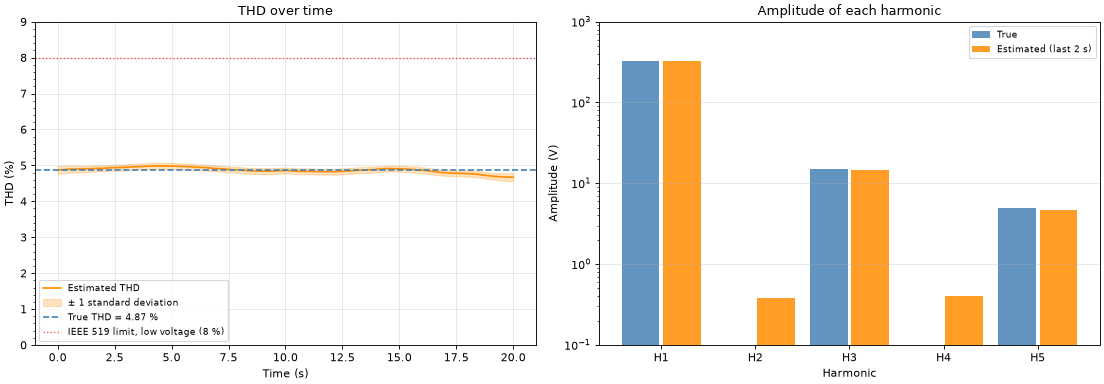

THD over the last 2 s: 4.71 ± 0.09 %   (true: 4.87 %)


In [9]:
import matplotlib.ticker as mticker

N_harm = grid.n_harmonics
A1_est = amplitudes[:, 0]
distortion = np.sqrt(np.sum(amplitudes[:, 1:]**2, axis=1))    # all harmonics above the fundamental
thd = 100 * distortion / (A1_est + 1e-12)

# Standard deviation of the THD, from the standard deviation of each amplitude
sigma_thd = np.zeros(len(t))
denom = (A1_est * distortion + 1e-12)
for k in range(1, N_harm):
    sigma_thd += (amplitudes[:, k] / denom)**2 * sigma_amp[:, k]**2
sigma_thd += (thd / 100 / (A1_est + 1e-12))**2 * sigma_amp[:, 0]**2
sigma_thd = 100 * np.sqrt(sigma_thd)

thd_true = 100 * np.sqrt(A3**2 + A5**2) / A1
last_amps = amplitudes[tail].mean(axis=0)
true_amps = np.array([A1, 0, A3, 0, A5])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.plot(t, thd, color="darkorange", lw=1.5, label="Estimated THD")
ax.fill_between(t, thd - sigma_thd, thd + sigma_thd, color="darkorange", alpha=0.25, label="± 1 standard deviation")
ax.axhline(thd_true, ls="--", color="steelblue", lw=1.5, label=f"True THD = {thd_true:.2f} %")
ax.axhline(8.0, ls=":", color="red", lw=1.2, alpha=0.7, label="IEEE 519 limit, low voltage (8 %)")
ax.set_xlabel("Time (s)")
ax.set_ylabel("THD (%)")
ax.set_ylim(0, 9)
ax.set_title("THD over time")
ax.yaxis.set_minor_locator(mticker.AutoMinorLocator())
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)

ax = axes[1]
x_pos = np.arange(1, N_harm + 1)
ax.bar(x_pos - 0.22, true_amps, 0.40, label="True", color="steelblue", alpha=0.85)
ax.bar(x_pos + 0.22, last_amps, 0.40, label="Estimated (last 2 s)", color="darkorange", alpha=0.85)
ax.set_yscale("log"); ax.set_ylim(0.1, 1000)
ax.set_xlabel("Harmonic")
ax.set_ylabel("Amplitude (V)")
ax.set_title("Amplitude of each harmonic")
ax.set_xticks(x_pos)
ax.set_xticklabels([f"H{k}" for k in range(1, N_harm + 1)])
ax.grid(True, axis="y", alpha=0.3)
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()
print(f"THD over the last 2 s: {thd[tail].mean():.2f} ± {sigma_thd[tail].mean():.2f} %   (true: {thd_true:.2f} %)")

## Step 8 — Detecting a Faulty Load

At t = 2.5 s a faulty load switches on and adds a second harmonic of 6.5 V, 2 % of the fundamental (Step 2). The filter should show H2 near zero before that moment and rising after it.

Two choices differ from Step 6. The forward filter is used alone, since a monitor cannot wait for later samples. And `process_uncertainty` is raised from 0.01 V to 0.05 V per sample, so that the filter accepts a quick change; the price is a noisier estimate.

The fault is declared when the H2 amplitude passes half of its final value.

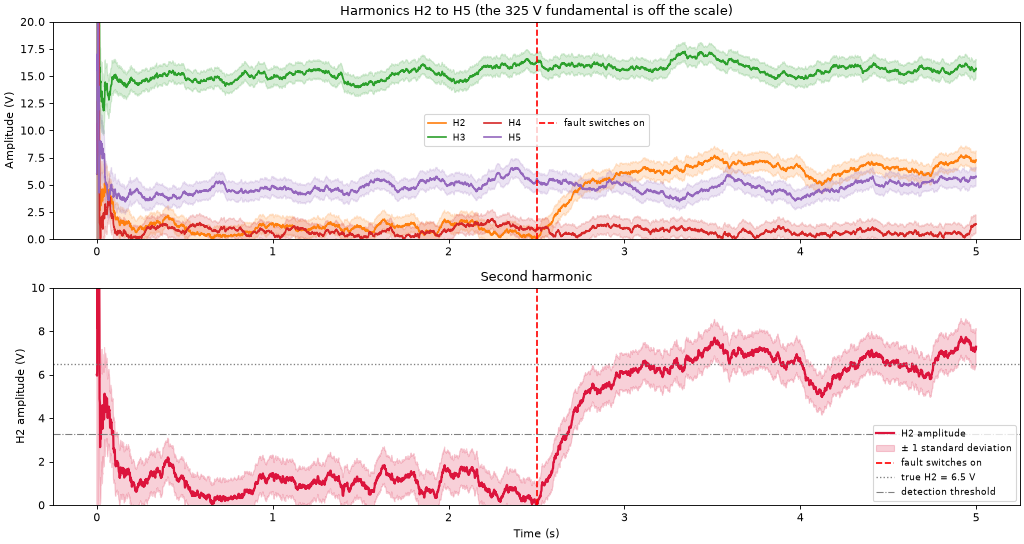

H2 before the fault (t = 1 s to 2.5 s): mean 1.0 V, largest 1.8 V
H2 passes 3.25 V at t = 2.675 s: 175 ms after the fault switches on


In [10]:
T_fault = 5.0       # duration [s]
t_f = np.arange(int(T_fault * fs)) / fs
fault_onset = 2.5   # the faulty load switches on [s]
V2_fault = 6.5      # second harmonic it adds [V]

np.random.seed(7)
v_fault = (A1 * np.cos(2 * np.pi * f0 * t_f) +
           A3 * np.cos(2 * np.pi * 3 * f0 * t_f + phi3) +
           A5 * np.cos(2 * np.pi * 5 * f0 * t_f + phi5) +
           np.random.normal(0, noise_std, len(t_f)))
idx_on = int(fault_onset * fs)
v_fault[idx_on:] += V2_fault * np.cos(2 * np.pi * 2 * f0 * t_f[idx_on:])

grid_f = PowerGridStateModel("L1_fault", f0=f0, harmonics=5, fs=fs,
                             measurement_uncertainty=noise_std,   # noise std [V]
                             process_uncertainty=0.05)            # drift per sample (std) [V]
grid_f.initial_state([[A1, 0], [0, 0], [0, 0], [0, 0], [0, 0]])
rec_f = grid_f.filter(v_fault, smooth=False, reset=True)          # forward filter only

amp_f, sig_f = grid_f.harmonic_envelope(rec_f)

fig, axes = plt.subplots(2, 1, figsize=(13, 7))

colors_h = plt.cm.tab10(np.arange(5) % 10)
for k in range(1, 5):
    axes[0].plot(t_f, amp_f[:, k], color=colors_h[k], lw=1.5, label=f"H{k + 1}")
    axes[0].fill_between(t_f, amp_f[:, k] - sig_f[:, k], amp_f[:, k] + sig_f[:, k],
                         color=colors_h[k], alpha=0.18)
axes[0].axvline(fault_onset, ls="--", color="red", lw=1.5, label="fault switches on")
axes[0].set_ylabel("Amplitude (V)")
axes[0].set_title("Harmonics H2 to H5 (the 325 V fundamental is off the scale)")
axes[0].legend(fontsize=8, ncol=3)
axes[0].set_ylim(0, 20)

axes[1].plot(t_f, amp_f[:, 1], color="crimson", lw=2, label="H2 amplitude")
axes[1].fill_between(t_f, amp_f[:, 1] - sig_f[:, 1], amp_f[:, 1] + sig_f[:, 1],
                     color="crimson", alpha=0.2, label="± 1 standard deviation")
axes[1].axvline(fault_onset, ls="--", color="red", lw=1.5, label="fault switches on")
axes[1].axhline(V2_fault, ls=":", color="gray", lw=1.2, label=f"true H2 = {V2_fault} V")
axes[1].axhline(V2_fault / 2, ls="-.", color="gray", lw=1.0, label="detection threshold")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("H2 amplitude (V)")
axes[1].set_ylim(0, 10)
axes[1].set_title("Second harmonic")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

threshold = V2_fault / 2
before = amp_f[int(1.0 * fs):idx_on, 1]
detect_idx = np.where((t_f > fault_onset) & (amp_f[:, 1] > threshold))[0]
print(f"H2 before the fault (t = 1 s to 2.5 s): mean {before.mean():.1f} V, largest {before.max():.1f} V")
print(f"H2 passes {threshold:.2f} V at t = {t_f[detect_idx[0]]:.3f} s: "
      f"{1000*(t_f[detect_idx[0]] - fault_onset):.0f} ms after the fault switches on")

The fault is detected within about ten mains cycles (one cycle is 20 ms). Before it, the H2 estimate is not exactly zero, because with the larger process noise it follows the measurement noise. Once the start-up of the first tenths of a second is over, it stays below the threshold.

## Extensions

- **Power per harmonic.** Track the current with a second `PowerGridStateModel`. The voltage and current phasors of harmonic $k$ then give its active and reactive power.
- **Frequency tracking.** The mains frequency is not exactly 50 Hz. Adding a frequency offset to the state would let the filter follow it.
- **Inter-harmonics.** Some loads, such as arc furnaces, add lines that are not multiples of $f_0$. `PhasorOscillatorModel` accepts any list of frequencies, so they can be tracked alongside the harmonics.